#Collecting Data

In [4]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("juanmerinobermejo/laptops-price-dataset")

# print("Path to dataset files:", path)

#Import library

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV #model evaluasi
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, StandardScaler #preprocess
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error #metric evaluasi
from sklearn.linear_model import LinearRegression, Ridge #algoritma
from sklearn.tree import DecisionTreeRegressor #algoritma
from lightgbm import LGBMRegressor #algoritma
from xgboost import XGBRegressor #algoritma

#Overview Data

In [6]:
df = pd.read_csv('laptops.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Laptop        2160 non-null   object 
 1   Status        2160 non-null   object 
 2   Brand         2160 non-null   object 
 3   Model         2160 non-null   object 
 4   CPU           2160 non-null   object 
 5   RAM           2160 non-null   int64  
 6   Storage       2160 non-null   int64  
 7   Storage type  2118 non-null   object 
 8   GPU           789 non-null    object 
 9   Screen        2156 non-null   float64
 10  Touch         2160 non-null   object 
 11  Final Price   2160 non-null   float64
dtypes: float64(2), int64(2), object(8)
memory usage: 202.6+ KB


In [7]:
df.head()

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
0,ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core...,New,Asus,ExpertBook,Intel Core i5,8,512,SSD,NaN,15.6,No,1009.00
1,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,NaN,15.6,No,299.00
2,ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core...,New,Asus,ExpertBook,Intel Core i3,8,256,SSD,NaN,15.6,No,789.00
3,MSI Katana GF66 12UC-082XES Intel Core i7-1270...,New,MSI,Katana,Intel Core i7,16,1000,SSD,RTX 3050,15.6,No,1199.00
4,HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB...,New,HP,15S,Intel Core i5,16,512,SSD,NaN,15.6,No,669.01


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isna().sum()

Laptop             0
Status             0
Brand              0
Model              0
CPU                0
RAM                0
Storage            0
Storage type      42
GPU             1371
Screen             4
Touch              0
Final Price        0
dtype: int64

In [10]:
df.describe()

,RAM,Storage,Screen,Final Price
count,2160.000000,2160.000000,2156.000000,2160.000000
mean,15.413889,596.294444,15.168112,1312.638509
std,9.867815,361.220506,1.203329,911.475417
min,4.000000,0.000000,10.100000,201.050000
25%,8.000000,256.000000,14.000000,661.082500
50%,16.000000,512.000000,15.600000,1031.945000
75%,16.000000,1000.000000,15.600000,1708.970000
max,128.000000,4000.000000,18.000000,7150.470000


#Cleaning Data

## Standarized Brand Names

In [11]:
df['Brand'] = df['Brand'].str.strip().str.title()
df['Brand'] = df['Brand'].replace({'Asus': 'ASUS', 'Apple': 'Apple', 'Hp': 'HP'})

## Clean GPU Spacing

In [12]:
df['GPU'] = df['GPU'].str.replace(r'([A-Za-z])(\d)', r'\1 \2', regex=True).str.strip()
df['GPU'] = df['GPU'].fillna('Integrated')

## Missing Storage Types

In [13]:
df['Storage type'] = df['Storage type'].fillna('Unknown')

## Missing Screen Size

In [14]:
df['Screen'] = df['Screen'].fillna(df['Screen'].mode()[0])

## Convert Data Types

In [15]:
df['RAM'] = pd.to_numeric(df['RAM'], errors='coerce')
df['Storage'] = pd.to_numeric(df['Storage'], errors='coerce')
df['Final Price'] = pd.to_numeric(df['Final Price'], errors='coerce')
df['Touch'] = df['Touch'].map({'Yes': 1, 'No': 0})

In [16]:
df.isna().sum()

Laptop          0
Status          0
Brand           0
Model           0
CPU             0
RAM             0
Storage         0
Storage type    0
GPU             0
Screen          0
Touch           0
Final Price     0
dtype: int64

In [17]:
df.head()

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
0,ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core...,New,ASUS,ExpertBook,Intel Core i5,8,512,SSD,Integrated,15.6,0,1009.00
1,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,Integrated,15.6,0,299.00
2,ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core...,New,ASUS,ExpertBook,Intel Core i3,8,256,SSD,Integrated,15.6,0,789.00
3,MSI Katana GF66 12UC-082XES Intel Core i7-1270...,New,Msi,Katana,Intel Core i7,16,1000,SSD,RTX 3050,15.6,0,1199.00
4,HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB...,New,HP,15S,Intel Core i5,16,512,SSD,Integrated,15.6,0,669.01


In [18]:
df.describe()

,RAM,Storage,Screen,Touch,Final Price
count,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000
mean,15.413889,596.294444,15.168912,0.105093,1312.638509
std,9.867815,361.220506,1.202357,0.306744,911.475417
min,4.000000,0.000000,10.100000,0.000000,201.050000
25%,8.000000,256.000000,14.000000,0.000000,661.082500
50%,16.000000,512.000000,15.600000,0.000000,1031.945000
75%,16.000000,1000.000000,15.600000,0.000000,1708.970000
max,128.000000,4000.000000,18.000000,1.000000,7150.470000


#EDA

Ukuran dataset: (2160, 12)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Laptop        2160 non-null   object 
 1   Status        2160 non-null   object 
 2   Brand         2160 non-null   object 
 3   Model         2160 non-null   object 
 4   CPU           2160 non-null   object 
 5   RAM           2160 non-null   int64  
 6   Storage       2160 non-null   int64  
 7   Storage type  2160 non-null   object 
 8   GPU           2160 non-null   object 
 9   Screen        2160 non-null   float64
 10  Touch         2160 non-null   int64  
 11  Final Price   2160 non-null   float64
dtypes: float64(2), int64(3), object(7)
memory usage: 202.6+ KB


,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
0,ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core...,New,ASUS,ExpertBook,Intel Core i5,8,512,SSD,Integrated,15.6,0,1009.00
1,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,Integrated,15.6,0,299.00
2,ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core...,New,ASUS,ExpertBook,Intel Core i3,8,256,SSD,Integrated,15.6,0,789.00
3,MSI Katana GF66 12UC-082XES Intel Core i7-1270...,New,Msi,Katana,Intel Core i7,16,1000,SSD,RTX 3050,15.6,0,1199.00
4,HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB...,New,HP,15S,Intel Core i5,16,512,SSD,Integrated,15.6,0,669.01


Jumlah baris duplikat: 0


,Jumlah Missing Value,Persentase Missing (%)
Laptop,0,0.0
Status,0,0.0
Brand,0,0.0
Model,0,0.0
CPU,0,0.0
RAM,0,0.0
Storage,0,0.0
Storage type,0,0.0
GPU,0,0.0
Screen,0,0.0


,count,mean,std,min,25%,50%,75%,max
RAM,2160.0,15.413889,9.867815,4.00,8.0000,16.000,16.00,128.00
Storage,2160.0,596.294444,361.220506,0.00,256.0000,512.000,1000.00,4000.00
Screen,2160.0,15.168912,1.202357,10.10,14.0000,15.600,15.60,18.00
Touch,2160.0,0.105093,0.306744,0.00,0.0000,0.000,0.00,1.00
Final Price,2160.0,1312.638509,911.475417,201.05,661.0825,1031.945,1708.97,7150.47


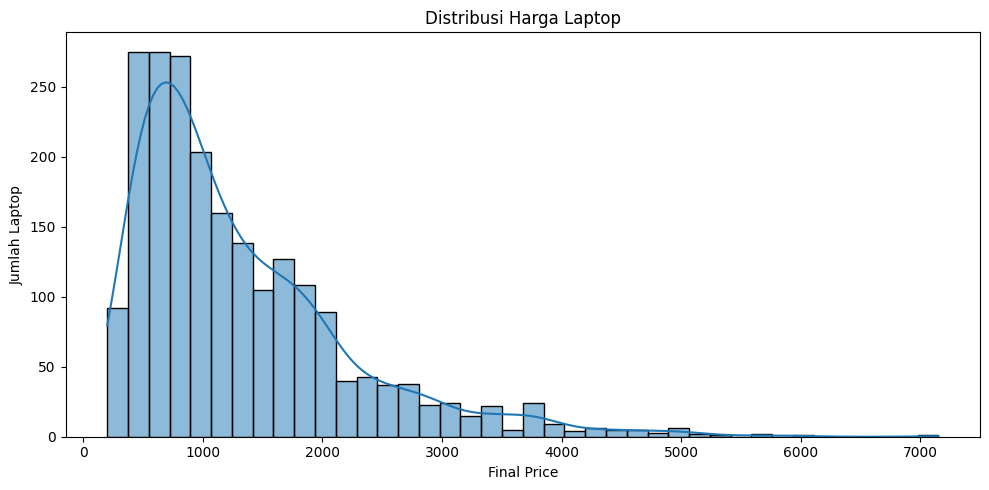

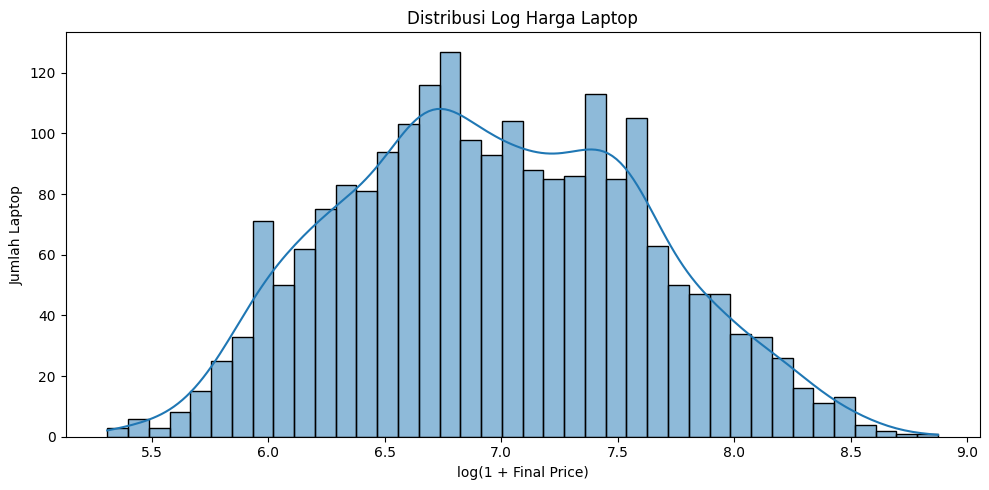

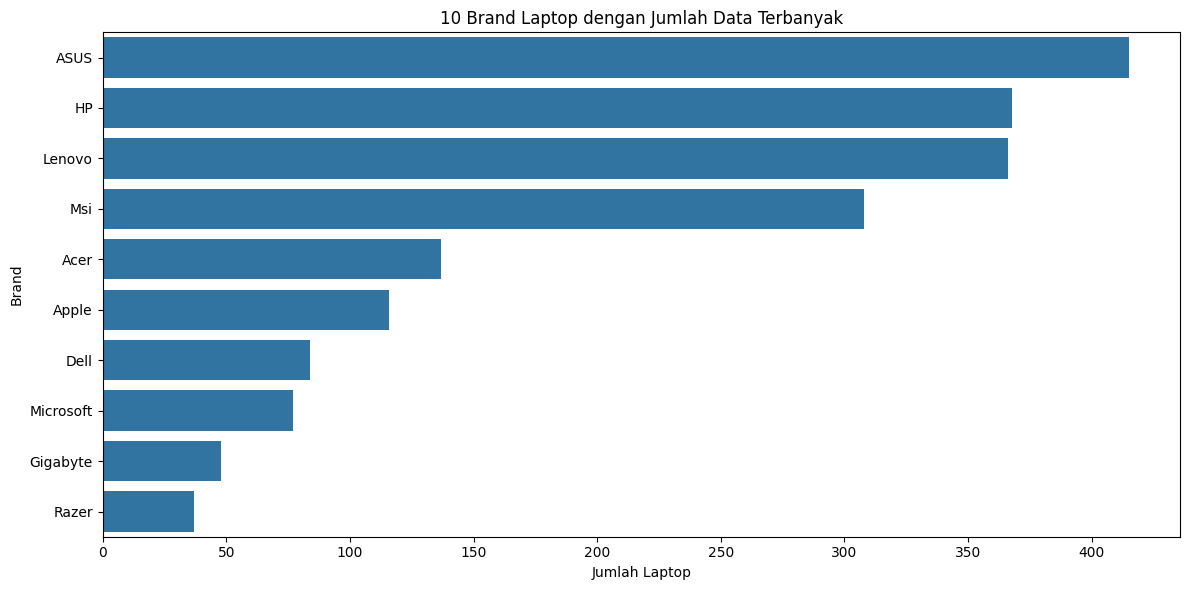

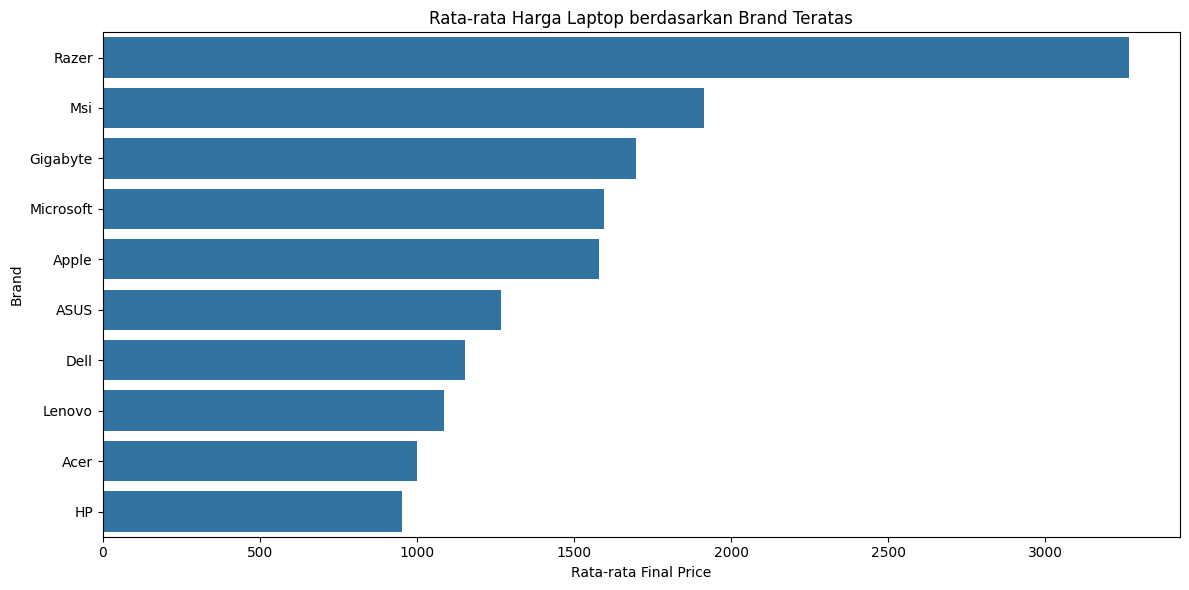

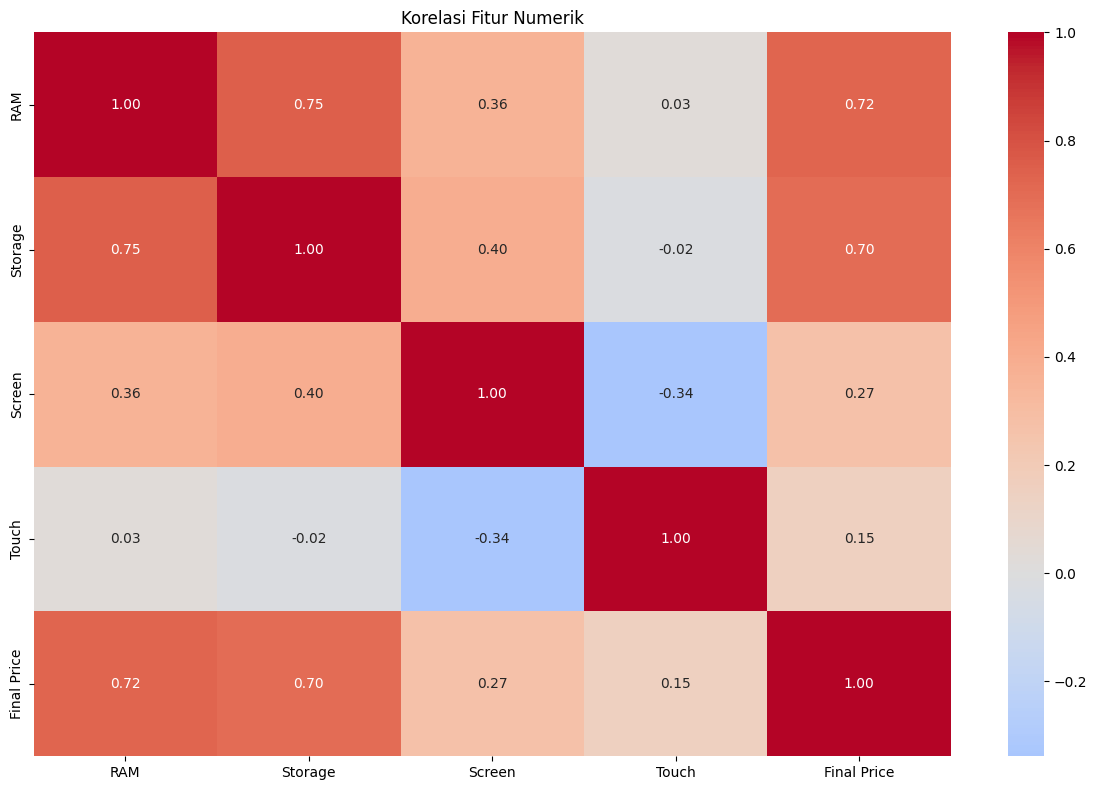

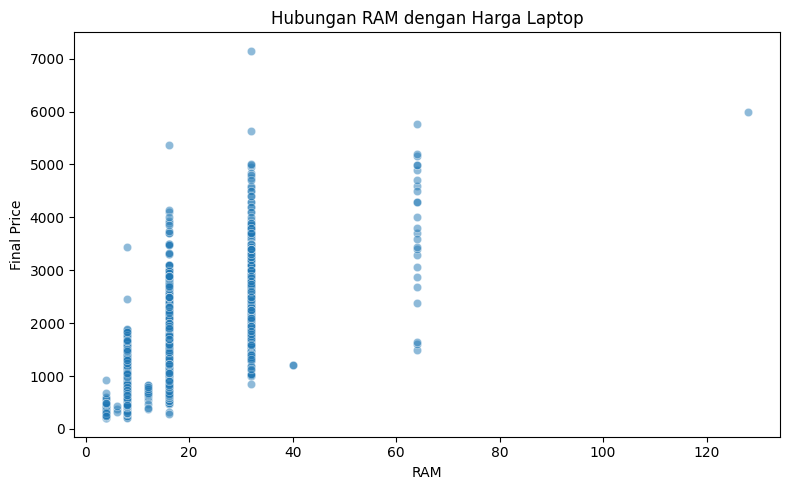

In [19]:
# ==========================================
# EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================

# 1. Melihat ukuran dataset dan tipe data
df_eda=df.copy()
print("Ukuran dataset:", df_eda.shape)
print("\nInformasi dataset:")
df_eda.info()

# 2. Melihat contoh data
display(df_eda.head())

# 3. Memeriksa data duplikat dan missing value
print("Jumlah baris duplikat:", df_eda.duplicated().sum())

missing_summary = pd.DataFrame({
    "Jumlah Missing Value": df_eda.isna().sum(),
    "Persentase Missing (%)": (df_eda.isna().mean() * 100).round(2)
}).sort_values("Jumlah Missing Value", ascending=False)

display(missing_summary)

# 4. Statistik deskriptif untuk kolom numerik
display(df_eda.describe().T)

# 5. Distribusi harga laptop
plt.figure(figsize=(10, 5))
sns.histplot(data=df_eda, x="Final Price", bins=40, kde=True)
plt.title("Distribusi Harga Laptop")
plt.xlabel("Final Price")
plt.ylabel("Jumlah Laptop")
plt.tight_layout()
plt.show()

# 6. Distribusi harga setelah transformasi log (membantu melihat kemencengan data)
plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(df_eda["Final Price"].dropna()), bins=40, kde=True)
plt.title("Distribusi Log Harga Laptop")
plt.xlabel("log(1 + Final Price)")
plt.ylabel("Jumlah Laptop")
plt.tight_layout()
plt.show()

# 7. Jumlah laptop berdasarkan brand (10 brand dengan jumlah terbanyak)
if "Brand" in df_eda.columns:
    plt.figure(figsize=(12, 6))
    brand_counts = df_eda["Brand"].value_counts().head(10)
    sns.barplot(x=brand_counts.values, y=brand_counts.index)
    plt.title("10 Brand Laptop dengan Jumlah Data Terbanyak")
    plt.xlabel("Jumlah Laptop")
    plt.ylabel("Brand")
    plt.tight_layout()
    plt.show()

# 8. Rata-rata harga untuk 10 brand dengan jumlah data terbanyak
if "Brand" in df_eda.columns:
    top_brands = df_eda["Brand"].value_counts().head(10).index
    brand_price = (
        df_eda[df_eda["Brand"].isin(top_brands)]
        .groupby("Brand", as_index=False)["Final Price"]
        .mean()
        .sort_values("Final Price", ascending=False)
    )
    plt.figure(figsize=(12, 6))
    sns.barplot(data=brand_price, x="Final Price", y="Brand")
    plt.title("Rata-rata Harga Laptop berdasarkan Brand Teratas")
    plt.xlabel("Rata-rata Final Price")
    plt.ylabel("Brand")
    plt.tight_layout()
    plt.show()

# 9. Korelasi antarfitur numerik
numeric_df_eda = df_eda.select_dtypes(include=np.number)
if numeric_df_eda.shape[1] > 1:
    plt.figure(figsize=(12, 8))
    sns.heatmap(numeric_df_eda.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
    plt.title("Korelasi Fitur Numerik")
    plt.tight_layout()
    plt.show()

# 10. Hubungan RAM dan harga laptop
if "RAM" in df_eda.columns and "Final Price" in df_eda.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df_eda, x="RAM", y="Final Price", alpha=0.5)
    plt.title("Hubungan RAM dengan Harga Laptop")
    plt.xlabel("RAM")
    plt.ylabel("Final Price")
    plt.tight_layout()
    plt.show()


#Preprocessing

##Feature Engineering

###Mengekstrak informasi dari fitur CPU

In [20]:
def categorize_cpu(cpu_name):
    cpu_name = str(cpu_name).lower()
    if 'i9' in cpu_name or 'ryzen 9' in cpu_name or 'm1 max' in cpu_name or 'm2 max' in cpu_name or 'm3 max' in cpu_name:
        return 'High-End'
    elif 'i7' in cpu_name or 'ryzen 7' in cpu_name or 'm1 pro' in cpu_name or 'm2 pro' in cpu_name or 'm3 pro' in cpu_name or 'm1' in cpu_name or 'm2' in cpu_name or 'm3' in cpu_name:
        return 'Mid-High'
    elif 'i5' in cpu_name or 'ryzen 5' in cpu_name:
        return 'Medium'
    elif 'i3' in cpu_name or 'ryzen 3' in cpu_name:
        return 'Entry-Medium'
    else:
        return 'Budget'

df['CPU_Class'] = df['CPU'].apply(categorize_cpu)

###Menyederhanakan Brand GPU

In [21]:
def categorize_gpu(gpu_name):
    gpu_name = str(gpu_name).lower()
    if 'rtx' in gpu_name:
        return 'NVIDIA RTX'
    elif 'gtx' in gpu_name:
        return 'NVIDIA GTX'
    elif 'radeon' in gpu_name or 'rx' in gpu_name:
        return 'AMD Radeon'
    elif 'intel' in gpu_name or 'integrated' in gpu_name:
        return 'Intel Integrated'
    elif 'apple' in gpu_name:
        return 'Apple Silicon'
    else:
        return 'Other'

df['GPU_Class'] = df['GPU'].apply(categorize_gpu)

###Rasio RAM terhadap Storage

In [22]:
df['RAM_Storage_Ratio'] = df['RAM'] / (df['Storage'] + 1)

In [23]:
df[['CPU', 'CPU_Class', 'GPU', 'GPU_Class', 'RAM_Storage_Ratio']].head()

,CPU,CPU_Class,GPU,GPU_Class,RAM_Storage_Ratio
0,Intel Core i5,Medium,Integrated,Intel Integrated,0.015595
1,Intel Celeron,Budget,Integrated,Intel Integrated,0.031128
2,Intel Core i3,Entry-Medium,Integrated,Intel Integrated,0.031128
3,Intel Core i7,Mid-High,RTX 3050,NVIDIA RTX,0.015984
4,Intel Core i5,Medium,Integrated,Intel Integrated,0.031189


In [24]:
df.head()

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price,CPU_Class,GPU_Class,RAM_Storage_Ratio
0,ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core...,New,ASUS,ExpertBook,Intel Core i5,8,512,SSD,Integrated,15.6,0,1009.00,Medium,Intel Integrated,0.015595
1,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,Integrated,15.6,0,299.00,Budget,Intel Integrated,0.031128
2,ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core...,New,ASUS,ExpertBook,Intel Core i3,8,256,SSD,Integrated,15.6,0,789.00,Entry-Medium,Intel Integrated,0.031128
3,MSI Katana GF66 12UC-082XES Intel Core i7-1270...,New,Msi,Katana,Intel Core i7,16,1000,SSD,RTX 3050,15.6,0,1199.00,Mid-High,NVIDIA RTX,0.015984
4,HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB...,New,HP,15S,Intel Core i5,16,512,SSD,Integrated,15.6,0,669.01,Medium,Intel Integrated,0.031189


In [25]:
df.drop(columns=['Laptop'], inplace=True)

###Split train validation

In [26]:
X = df.drop(columns=['Final Price']).copy()
y = np.log1p(df['Final Price'])

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [28]:
X_train = X_train.reset_index(drop=True)
X_test   = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test   = y_test.reset_index(drop=True)

print(f"X_train : {X_train.shape}")
print(f"X_test   : {X_test.shape}")

X_train : (1728, 13)
X_test   : (432, 13)


In [29]:
X_train.head()

,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,CPU_Class,GPU_Class,RAM_Storage_Ratio
0,Refurbished,ASUS,F515,Intel Core i7,8,512,SSD,Integrated,15.6,0,Mid-High,Intel Integrated,0.015595
1,New,HP,Chromebook,Intel Celeron,4,64,eMMC,Integrated,14.0,1,Budget,Intel Integrated,0.061538
2,New,ASUS,ROG,AMD Ryzen 7,16,512,SSD,RTX 3050,15.6,0,Mid-High,NVIDIA RTX,0.031189
3,Refurbished,ASUS,ROG,Intel Core i7,16,1000,SSD,RTX 2070,15.6,0,Mid-High,NVIDIA RTX,0.015984
4,Refurbished,Gigabyte,Aorus,Intel Core i7,16,512,SSD,RTX 2070,15.6,0,Mid-High,NVIDIA RTX,0.031189


In [30]:
y_train.head()

0    6.551080
1    5.991465
2    6.814532
3    7.148416
4    6.953627
Name: Final Price, dtype: float64

In [31]:
categorical_cols = X_train.select_dtypes(exclude=['int64', 'float64']).columns
numerical_cols = X_train.select_dtypes(exclude=['object']).columns

print(f"Kolom Categorik\n{categorical_cols}")
print(f"Kolom Numerik\n{numerical_cols}")

Kolom Categorik
Index(['Status', 'Brand', 'Model', 'CPU', 'Storage type', 'GPU', 'CPU_Class',
       'GPU_Class'],
      dtype='object')
Kolom Numerik
Index(['RAM', 'Storage', 'Screen', 'Touch', 'RAM_Storage_Ratio'], dtype='object')


##Encoding

###Target Encoding

In [32]:
train_temp = X_train.copy()
train_temp['Final Price'] = y_train

In [33]:
def oof_target_encoding(X_train, y_train, X_val, cols, n_splits=5, smoothing=10, random_state=42):

    X_train = X_train.copy()
    X_val = X_val.copy()

    global_mean = y_train.mean()

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    for col in cols:

        oof_encoded = np.zeros(len(X_train))

        for train_idx, val_idx in kf.split(X_train):

            X_tr = X_train.iloc[train_idx]
            y_tr = y_train.iloc[train_idx]

            temp = pd.DataFrame({col: X_tr[col], 'target': y_tr})

            stats = temp.groupby(col)['target'].agg(mean='mean', count='count')

            encoded_map = (stats['count'] * stats['mean']+ smoothing * global_mean) / (stats['count'] + smoothing)

            oof_encoded[val_idx] = (X_train.iloc[val_idx][col].map(encoded_map).fillna(global_mean))

        X_train[f'{col}_te'] = oof_encoded

        # Encoding untuk TEST menggunakan seluruh training set
        temp_full = pd.DataFrame({col: X_train[col], 'target': y_train})

        stats_full = temp_full.groupby(col)['target'].agg(mean='mean', count='count')

        encoded_map_full = (stats_full['count'] * stats_full['mean']+ smoothing * global_mean) / (stats_full['count'] + smoothing)

        X_val[f'{col}_te'] = (X_val[col].map(encoded_map_full).fillna(global_mean))

    return X_train, X_val

In [34]:
cols_target_encode = ['Brand', 'Model', 'CPU', 'GPU']

X_train, X_test = oof_target_encoding(X_train, y_train, X_test, cols=cols_target_encode, n_splits=5, smoothing=10)

In [35]:
X_train.drop(columns=['Brand'], inplace=True)
X_test.drop(columns=['Brand'], inplace=True)
X_train.drop(columns=['Model'], inplace=True)
X_test.drop(columns=['Model'], inplace=True)
X_train.drop(columns=['CPU'], inplace=True)
X_test.drop(columns=['CPU'], inplace=True)
X_train.drop(columns=['GPU'], inplace=True)
X_test.drop(columns=['GPU'], inplace=True)

###Label Encoding

In [36]:
le = LabelEncoder()

# Status
le.fit(X_train['Status'])
X_train['Status'] = le.transform(X_train['Status'])
X_test['Status'] = le.transform(X_test['Status'])

###OHE

In [37]:
ohe_cols = ['Storage type', 'GPU_Class']
ohe_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

encoded_train = ohe_encoder.fit_transform(X_train[ohe_cols])

encoded_train_df = pd.DataFrame(encoded_train, columns=ohe_encoder.get_feature_names_out(ohe_cols), index=X_train.index)

X_train = pd.concat([X_train.drop(columns=ohe_cols), encoded_train_df], axis=1)

encoded_test = ohe_encoder.transform(X_test[ohe_cols])

encoded_test_df = pd.DataFrame(encoded_test, columns=ohe_encoder.get_feature_names_out(ohe_cols), index=X_test.index)

X_test = pd.concat([X_test.drop(columns=ohe_cols), encoded_test_df], axis=1)

###Ordinal Encoding

In [38]:
df['CPU_Class'].value_counts()

CPU_Class
Mid-High        1012
Medium           692
Entry-Medium     174
Budget           143
High-End         139
Name: count, dtype: int64

In [39]:
ordinalencode = OrdinalEncoder()
kategori_cpu = [['Budget', 'Entry-Medium', 'Medium', 'Mid-High', 'High-End']]
X_train['CPU_Class_Encoded'] = ordinalencode.fit_transform(X_train[['CPU_Class']])
X_test['CPU_Class_Encoded'] = ordinalencode.transform(X_test[['CPU_Class']])

X_train.drop(columns=['CPU_Class'], inplace=True)
X_test.drop(columns=['CPU_Class'], inplace=True)

In [40]:
X_train.head()

,Status,RAM,Storage,Screen,Touch,RAM_Storage_Ratio,Brand_te,Model_te,CPU_te,GPU_te,Storage type_SSD,Storage type_Unknown,Storage type_eMMC,GPU_Class_AMD Radeon,GPU_Class_Intel Integrated,GPU_Class_NVIDIA GTX,GPU_Class_NVIDIA RTX,GPU_Class_Other,CPU_Class_Encoded
0,1,8,512,15.6,0,0.015595,6.899490,6.618526,7.296797,6.681707,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,4.0
1,0,4,64,14.0,1,0.061538,6.664933,6.301956,6.023743,6.681614,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0,16,512,15.6,0,0.031189,6.899490,7.557502,6.945048,7.186843,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0
3,1,16,1000,15.6,0,0.015984,6.899490,7.557502,7.296797,7.126935,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0
4,1,16,512,15.6,0,0.031189,7.234615,7.072320,7.300004,7.116021,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0


In [41]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1728, 19)
(432, 19)
(1728,)
(432,)


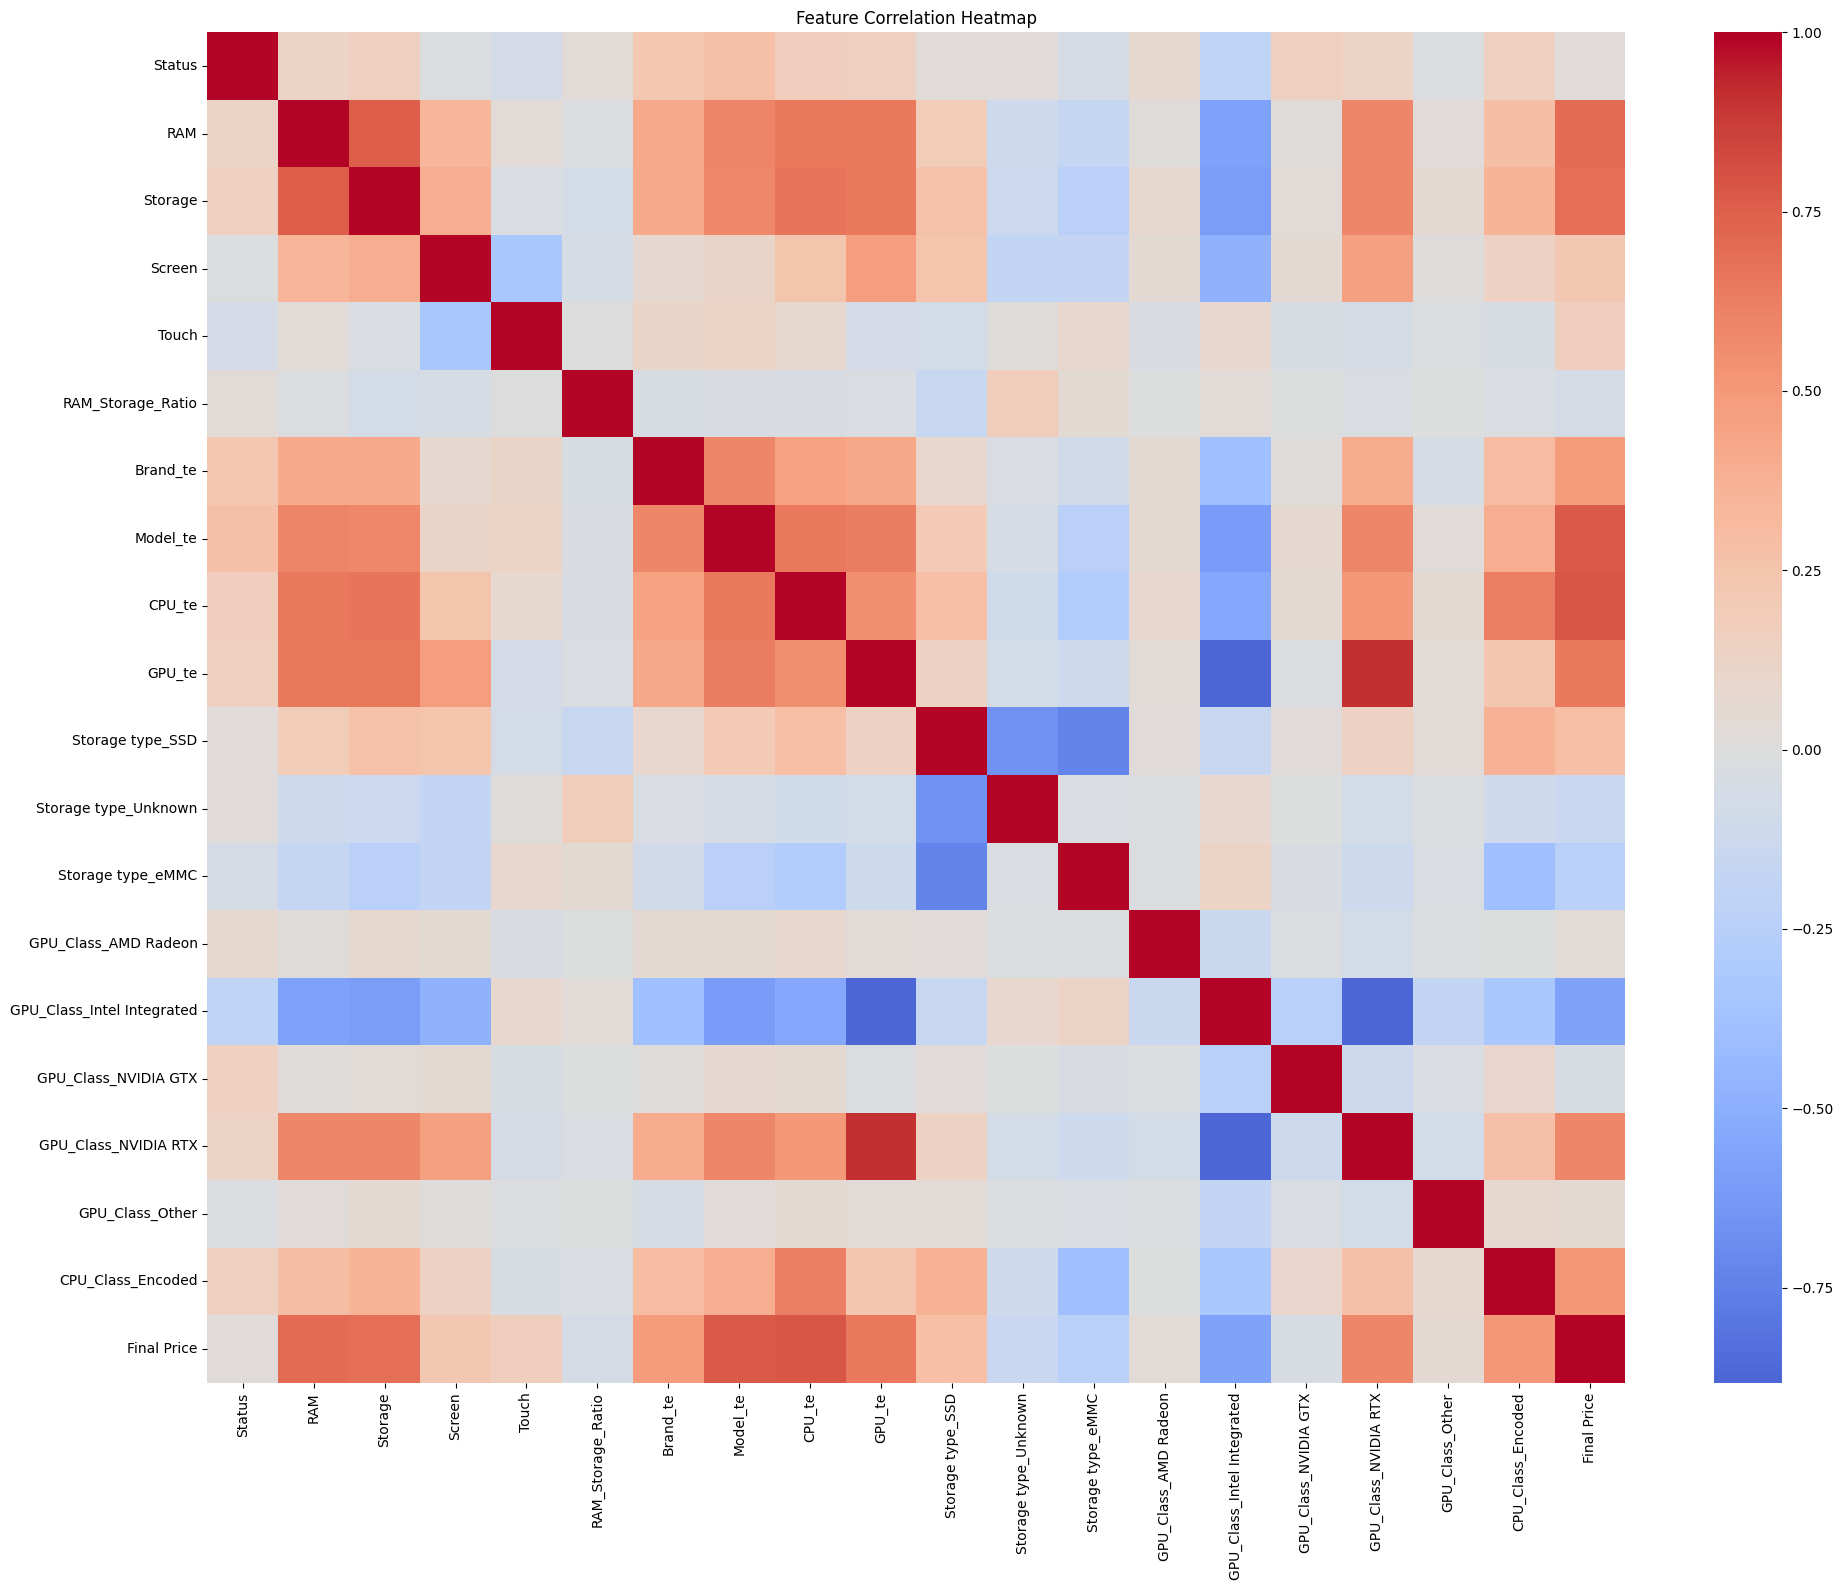

In [42]:
df_corr = X_train.copy()
df_corr['Final Price'] = y_train

corr_matrix = df_corr.corr()

plt.figure(figsize=(20,16))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, annot=False)

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

##Feature Selection

In [43]:
# from sklearn.feature_selection import SelectKBest, f_regression

# # Inisialisasi dan fit SelectKBest
# selector = SelectKBest(score_func=f_regression, k='all')
# selector.fit(X_train, y_train)

# # Buat DataFrame untuk melihat Skor Pengaruh dan P-Value
# fitur_evaluasi = pd.DataFrame({
#     'Fitur': X_train.columns,
#     'Skor_Pengaruh': selector.scores_,
#     'P_Value': selector.pvalues_
# }).sort_values(by='P_Value', ascending=True)

# print("=== HASIL SELEKSI FITUR (F-SCORE & P-VALUE) ===")

# # Gunakan .style.format() untuk mengatur tampilan masing-masing kolom
# tabel_rapi = fitur_evaluasi.style.format({
#     'Skor_Pengaruh': '{:.3f}',  # Angka desimal biasa (3 angka di belakang koma)
#     'P_Value': '{:.5e}'         # Notasi ilmiah (5 angka di belakang koma)
# })

# # Tampilkan tabel yang sudah diformat
# display(tabel_rapi)

# # 1. Buat list kolom yang tidak signifikan (P-Value >= 0.05)
# kolom_tidak_signifikan = fitur_evaluasi[fitur_evaluasi['P_Value'] >= 0.05]['Fitur'].tolist()

# print("\n=== DAFTAR KOLOM YANG AKAN DI-DROP (P-Value >= 0.05) ===")
# print(kolom_tidak_signifikan)

# # 2. Drop kolom TANPA inplace=True dan simpan ke variabel baru
# X_train_bersih = X_train.drop(columns=kolom_tidak_signifikan)
# X_val_bersih = X_val.drop(columns=kolom_tidak_signifikan)

# # 3. Cek jumlah kolom setelah di-drop
# print(f"\nJumlah kolom X_train awal: {X_train.shape[1]}")
# print(f"Jumlah kolom X_train_bersih sekarang: {X_train_bersih.shape[1]}")
# print(f"Jumlah kolom X_val_bersih sekarang: {X_val_bersih.shape[1]}")

#Model Evaluation

In [44]:
results = {}
def evaluate_model(model_name, X_train, y_train, X_test, y_test, model):
  kf = KFold(n_splits=5, shuffle=True, random_state=42)

  cross_val_r2 = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2')
  cross_val_rmse = cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')

  print(f'\n===== {model_name} =====')
  print(f'Cross Validation R2: {cross_val_r2.mean():.4f}')
  print(f'Cross Validation RMSE: {-cross_val_rmse.mean():.4f}')

  model.fit(X_train, y_train)
  y_train_pred = model.predict(X_train)
  y_test_pred = model.predict(X_test)

  r2_train = r2_score(y_train, y_train_pred)
  rmse_train = np.sqrt(mean_squared_error((y_train), (y_train_pred)))
  r2_test = r2_score(y_test, y_test_pred)
  rmse_test = np.sqrt(mean_squared_error((y_test), (y_test_pred)))

  results[model_name] = {
    'model': model,
    'r2_train': r2_train,
    'rmse_train': rmse_train,
    'r2_test': r2_test,
    'rmse_test': rmse_test
  }
  print(f'R2 Train: {r2_train:.4f}')
  print(f'RMSE Train: {rmse_train:.4f}')
  print(f'R2 Test: {r2_test:.4f}')
  print(f'RMSE Test: {rmse_test:.4f}')

In [45]:
model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

evaluate_model('Linear Regression', X_train, y_train, X_test, y_test, model)


===== Linear Regression =====
Cross Validation R2: 0.7882
Cross Validation RMSE: 0.2946
R2 Train: 0.8188
RMSE Train: 0.2742
R2 Test: 0.8260
RMSE Test: 0.2754


In [46]:
model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

evaluate_model('Ridge Regression', X_train, y_train, X_test, y_test, model)


===== Ridge Regression =====
Cross Validation R2: 0.7883
Cross Validation RMSE: 0.2945
R2 Train: 0.8188
RMSE Train: 0.2742
R2 Test: 0.8260
RMSE Test: 0.2754


In [47]:
model = Pipeline([
    ('model', DecisionTreeRegressor(random_state=42))
])

evaluate_model('Decision Tree Regressor', X_train, y_train, X_test, y_test, model)


===== Decision Tree Regressor =====
Cross Validation R2: 0.7206
Cross Validation RMSE: 0.3388
R2 Train: 0.9890
RMSE Train: 0.0676
R2 Test: 0.7190
RMSE Test: 0.3499


In [48]:
model = Pipeline([
    ('model', XGBRegressor(random_state=42))
])

evaluate_model('XGB Regressor', X_train, y_train, X_test, y_test, model)


===== XGB Regressor =====
Cross Validation R2: 0.8395
Cross Validation RMSE: 0.2571
R2 Train: 0.9780
RMSE Train: 0.0956
R2 Test: 0.8419
RMSE Test: 0.2625


In [49]:
model = Pipeline([
    ('model', LGBMRegressor(random_state=42))
])

evaluate_model('LGBM', X_train, y_train, X_test, y_test, model)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000683 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 511
[LightGBM] [Info] Number of data points in the train set: 1382, number of used features: 18
[LightGBM] [Info] Start training from score 6.972387
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000259 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 504
[LightGBM] [Info] Number of data points in the train set: 1382, number of used features: 18
[LightGBM] [Info] Start training from score 6.944343
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info

In [50]:
!pip install catboost

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


In [51]:
from catboost import CatBoostRegressor

In [52]:
model = Pipeline([
    ('model', CatBoostRegressor(verbose=0, random_state=42))
])

evaluate_model('CatBoost', X_train, y_train, X_test, y_test, model)


===== CatBoost =====
Cross Validation R2: 0.8605
Cross Validation RMSE: 0.2395
R2 Train: 0.9437
RMSE Train: 0.1528
R2 Test: 0.8710
RMSE Test: 0.2371


In [53]:
summary = pd.DataFrame({
    name: {
        'Train R2': f"{values['r2_train']:.4f}",
        'Train RMSE': f"{values['rmse_train']:.4f}",
        'Test R2': f"{values['r2_test']:.4f}",
        'Test RMSE': f"{values['rmse_test']:.4f}"
    }
    for name, values in results.items()
}).T.sort_values(by='Test R2', ascending=False)

print(summary)

                        Train R2 Train RMSE Test R2 Test RMSE
CatBoost                  0.9437     0.1528  0.8710    0.2371
LGBM                      0.9411     0.1563  0.8544    0.2519
XGB Regressor             0.9780     0.0956  0.8419    0.2625
Linear Regression         0.8188     0.2742  0.8260    0.2754
Ridge Regression          0.8188     0.2742  0.8260    0.2754
Decision Tree Regressor   0.9890     0.0676  0.7190    0.3499


In [54]:
best_model = CatBoostRegressor(random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cross_val_r2 = cross_val_score(best_model, X_train, y_train, cv=kf, scoring='r2')
cross_val_rmse = cross_val_score(best_model, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')

print(f'Cross Validation R2: {cross_val_r2.mean():.4f}')
print(f'Cross Validation RMSE: {-cross_val_rmse.mean():.4f}')

best_model.fit(X_train, y_train)
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

r2_train = r2_score(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error((y_train), (y_train_pred)))
r2_test = r2_score(y_test, y_test_pred)
rmse_test = np.sqrt(mean_squared_error((y_test), (y_test_pred)))

print(f'R2 Train: {r2_train:.4f}')
print(f'RMSE Train: {rmse_train:.4f}')
print(f'R2 Test: {r2_test:.4f}')
print(f'RMSE Test: {rmse_test:.4f}')

Learning rate set to 0.04309
0:	learn: 0.6258040	total: 1.17ms	remaining: 1.16s
1:	learn: 0.6077632	total: 2.28ms	remaining: 1.14s
2:	learn: 0.5902039	total: 3.17ms	remaining: 1.05s
3:	learn: 0.5736484	total: 4.17ms	remaining: 1.04s
4:	learn: 0.5574400	total: 5.13ms	remaining: 1.02s
5:	learn: 0.5427128	total: 6.02ms	remaining: 998ms
6:	learn: 0.5288281	total: 6.86ms	remaining: 973ms
7:	learn: 0.5151860	total: 7.85ms	remaining: 974ms
8:	learn: 0.5027281	total: 8.89ms	remaining: 979ms
9:	learn: 0.4905894	total: 10.1ms	remaining: 996ms
10:	learn: 0.4784885	total: 11.1ms	remaining: 994ms
11:	learn: 0.4682910	total: 12ms	remaining: 986ms
12:	learn: 0.4577093	total: 12.9ms	remaining: 979ms
13:	learn: 0.4481122	total: 13.9ms	remaining: 981ms
14:	learn: 0.4388215	total: 15ms	remaining: 988ms
15:	learn: 0.4294704	total: 16.1ms	remaining: 989ms
16:	learn: 0.4211255	total: 17.2ms	remaining: 996ms
17:	learn: 0.4124154	total: 18.3ms	remaining: 1000ms
18:	learn: 0.4046908	total: 19.3ms	remaining: 99

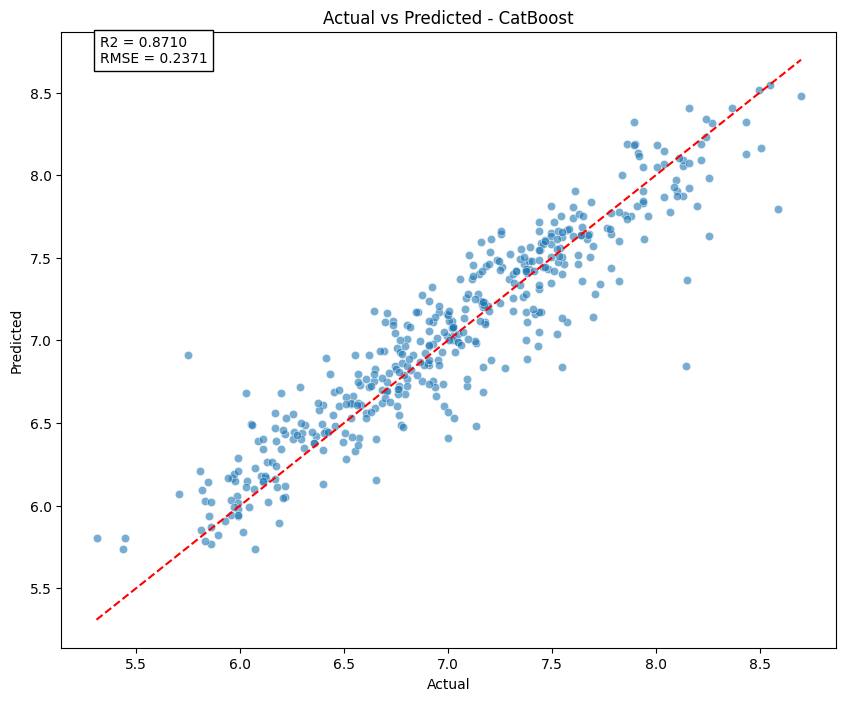

In [55]:
plt.figure(figsize=(10,8))

sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.6)

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')

plt.text(0.05, 0.95, f'R2 = {r2_test:.4f}\nRMSE = {rmse_test:.4f}', transform=plt.gca().transAxes, bbox=dict(facecolor='white'))

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted - CatBoost')
plt.show()

##Tuning

###Ridge

In [56]:
ridge_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

ridge_param_grid = {
    'model__alpha': [0.01, 0.1, 1, 5, 10, 20, 50, 100]
}

ridge_grid = GridSearchCV(
    ridge_pipe,
    ridge_param_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='r2',
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

print('Best Ridge params:', ridge_grid.best_params_)
print('Best CV R2:', ridge_grid.best_score_)

best_ridge = ridge_grid.best_estimator_
evaluate_model('Ridge (Tuned)', X_train, y_train, X_test, y_test, best_ridge)

Best Ridge params: {'model__alpha': 100}
Best CV R2: 0.7909334529937648

===== Ridge (Tuned) =====
Cross Validation R2: 0.7909
Cross Validation RMSE: 0.2931
R2 Train: 0.8166
RMSE Train: 0.2759
R2 Test: 0.8243
RMSE Test: 0.2767


###XGB

In [57]:
xgb_param_grid = {
    'n_estimators': [600, 800],
    'max_depth': [5, 7],
    'learning_rate': [0.03, 0.05],
    'subsample': [0.8],
    'colsample_bytree': [0.8]
}

xgb_grid = GridSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1, tree_method='hist'),
    xgb_param_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='r2',
    n_jobs=1,
    verbose=1
)

xgb_grid.fit(X_train, y_train)

print('Best XGB params:', xgb_grid.best_params_)
print('Best CV R2:', xgb_grid.best_score_)

best_xgb = xgb_grid.best_estimator_
evaluate_model('XGB (Tuned)', X_train, y_train, X_test, y_test, best_xgb)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best XGB params: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 600, 'subsample': 0.8}
Best CV R2: 0.8579673667361336

===== XGB (Tuned) =====
Cross Validation R2: 0.8580
Cross Validation RMSE: 0.2418
R2 Train: 0.9538
RMSE Train: 0.1385
R2 Test: 0.8650
RMSE Test: 0.2426


###LGBM

In [58]:
lgbm_param_grid = {
    'n_estimators': [800],
    'num_leaves': [31, 63],
    'learning_rate': [0.03, 0.05],
    'subsample': [0.8],
    'colsample_bytree': [0.8]
}

lgbm_grid = GridSearchCV(
    LGBMRegressor(random_state=42, n_jobs=-1, verbosity=-1),
    lgbm_param_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='r2',
    n_jobs=1,
    verbose=1
)

lgbm_grid.fit(X_train, y_train)

print('Best LGBM params:', lgbm_grid.best_params_)
print('Best CV R2:', lgbm_grid.best_score_)

best_lgbm = lgbm_grid.best_estimator_
evaluate_model('LGBM (Tuned)', X_train, y_train, X_test, y_test, best_lgbm)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best LGBM params: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'n_estimators': 800, 'num_leaves': 31, 'subsample': 0.8}
Best CV R2: 0.8570994874834753

===== LGBM (Tuned) =====
Cross Validation R2: 0.8571
Cross Validation RMSE: 0.2423
R2 Train: 0.9600
RMSE Train: 0.1289
R2 Test: 0.8569
RMSE Test: 0.2497


###CatBoost

In [59]:
cat_param_grid = {
    'iterations': [600, 800],
    'depth': [6, 8],
    'learning_rate': [0.03, 0.05],
    'l2_leaf_reg': [3, 7]
}

cat_grid = GridSearchCV(
    CatBoostRegressor(random_state=42, verbose=0),
    cat_param_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='r2',
    n_jobs=1,
    verbose=1
)

cat_grid.fit(X_train, y_train)

print('Best CatBoost params:', cat_grid.best_params_)
print('Best CV R2:', cat_grid.best_score_)

best_cat = cat_grid.best_estimator_
evaluate_model('CatBoost (Tuned)', X_train, y_train, X_test, y_test, best_cat)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best CatBoost params: {'depth': 6, 'iterations': 800, 'l2_leaf_reg': 3, 'learning_rate': 0.03}
Best CV R2: 0.8601862795511707

===== CatBoost (Tuned) =====
Cross Validation R2: 0.8602
Cross Validation RMSE: 0.2399
R2 Train: 0.9243
RMSE Train: 0.1772
R2 Test: 0.8681
RMSE Test: 0.2397


In [60]:
!pip install optuna

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


In [63]:
summary_with_tuned = pd.DataFrame({
    name: {
        'Train R2': f"{values['r2_train']:.4f}",
        'Train RMSE': f"{values['rmse_train']:.4f}",
        'Test R2': f"{values['r2_test']:.4f}",
        'Test RMSE': f"{values['rmse_test']:.4f}"
    }
    for name, values in results.items()
}).T.sort_values(by='Test R2', ascending=False)

summary_with_tuned

,Train R2,Train RMSE,Test R2,Test RMSE
CatBoost,0.9437,0.1528,0.8710,0.2371
CatBoost (Tuned),0.9243,0.1772,0.8681,0.2397
XGB (Tuned),0.9538,0.1385,0.8650,0.2426
LGBM (Tuned),0.9600,0.1289,0.8569,0.2497
LGBM,0.9411,0.1563,0.8544,0.2519
XGB Regressor,0.9780,0.0956,0.8419,0.2625
Linear Regression,0.8188,0.2742,0.8260,0.2754
Ridge Regression,0.8188,0.2742,0.8260,0.2754
Ridge (Tuned),0.8166,0.2759,0.8243,0.2767
Decision Tree Regressor,0.9890,0.0676,0.7190,0.3499


In [64]:
best_model_name = summary_with_tuned.index[0]
print(f"Best Model: {best_model_name}")

Best Model: CatBoost


In [65]:
pred = np.expm1(best_model.predict(X_test))
actual = np.expm1(y_test)

mae = mean_absolute_error(actual, pred)

print(f"MAE {best_model_name}: {mae:,.0f} Euros")

MAE CatBoost: 242 Euros


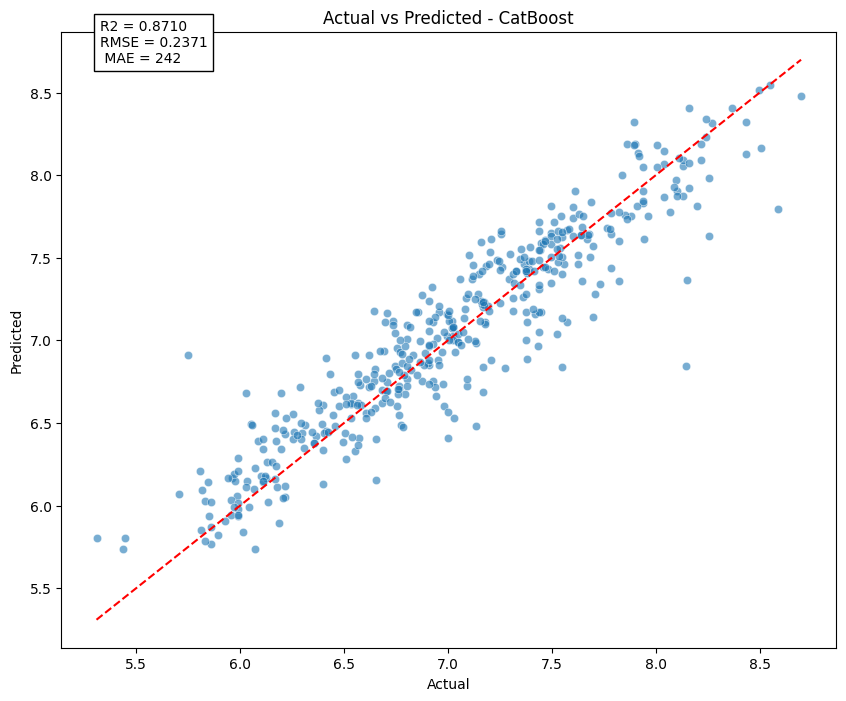

In [66]:
plt.figure(figsize=(10,8))

sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.6)

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')

plt.text(0.05, 0.95, f'R2 = {r2_test:.4f}\nRMSE = {rmse_test:.4f}\n MAE = {mae:,.0f}', transform=plt.gca().transAxes, bbox=dict(facecolor='white'))

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title(f'Actual vs Predicted - {best_model_name}')
plt.show()